# Tutorial 2 - Perturb-map held-out perturbation benchmark

The same held-out perturbation question as tutorial 1, on four sections of a spatial
Perturb-map (spatial Perturb-seq) assay. Running the benchmark on a second assay tests whether
the result depends on the measurement platform.

Read [tutorial 1](01_spac_seq_benchmark.ipynb) first - the two settings and the two metrics are
the same, and are explained there rather than repeated here.

### The reported scoring rule

The within-niche numbers are scored with the **disjoint reference**: the measured log fold change of a
record is the knockout cells of the niche against the **control cells of the niche that lie outside
every held-out patch** (patch role 0), with the slide's role-0 controls as the fallback when the
niche has fewer than 5. The held-out source spots are themselves labelled `control` on this assay,
so the evaluation harness's own reference (every control cell of the niche) can contain the very
cells being predicted; the disjoint reference is asserted to exclude them. Predictions are untouched -
the rescore applies the disjoint reference to the stored predicted LFCs of every method, CONCERT included (`benchmark_evaluation/score_perturbmap.py`).

### What differs from SPAC-seq

The model is the same one (`models/concert_benchmark`). The settings differ only where the two
assays differ:

| | SPAC-seq | Perturb-map |
|---|---|---|
| non-targeting control class | present | **absent** - unperturbed cells are the comparison group, `--control_label __NONE__` |
| guide assignment | ambiguous | unambiguous, so the technical correction is **off** (`use_action_correction=False`) |
| spot density | sparser, larger sections | denser, smaller sections |
| footprint inducing points | 16 | **64** |
| lengthscale band (normalized) | [0.15, 0.90] | **[0.01, 0.60]** |
| coordinate scale | 20 | **70** |
| minimum cells per perturbation | 25 | **0** - the panel is already balanced |

The inducing-point count and the training patience are not free choices: carrying over SPAC-seq's
16 inducing points and short patience costs about a third of the rank correlation on this assay.
64 points with patience 300 - the reported arm - is what the reported numbers come from,
and every one of its learned lengthscales sits inside the band rather than pinned at an end.

### Two extra traps specific to this assay

* **Scoring space.** CONCERT predicts its own 2000 highly-variable genes; the competitors score
  the 1053-gene assay panel. Scoring CONCERT over all 2000 measures spread over maximum-variance
  genes and inflates the error by an order of magnitude. The evaluation restricts to the
  panel overlap (~790 genes) so both sides are comparable.
* **Cell indexing.** The evaluation's prepared panel does not share barcodes or coordinates with
  the model's input files, so everything is scored in **model-row space** and the patch file is
  the bridge: patch cell -> section pixel coordinate -> array coordinate -> model row.

## 0. Before you start

Run on a GPU node in `concert_env`; see tutorial 1, section 0, for the session setup and the
GPU-compatibility note.

| Step | Time on one H100 |
|---|---|
| 2 - load checkpoint + one section | 1-3 min |
| 5 - one prediction | < 1 min |
| 6 - score one section | 5-15 min |
| 7, 8, 9 - reading shipped results | seconds |

## 1. Paths

`perturbmap_within_niche` (the reported arm of the lengthscale sweep) is the checkpoint the paper
reports, and `perturbmap_cross_slide` is its cross-slide counterpart. Both sit in the
`checkpoints/` folder.

In [1]:
import warnings, logging
warnings.filterwarnings("ignore")   # anndata/scanpy FutureWarning and library chatter
for _lib in ("anndata", "scanpy", "matplotlib", "numba", "torch", "h5py", "fontTools", "py.warnings"):
    logging.getLogger(_lib).setLevel(logging.ERROR)

import os, sys, json
from pathlib import Path
from types import SimpleNamespace

# code
# The repository root: the directory holding models/ and benchmark_evaluation/. Found by
# walking up from the working directory, so the notebook runs from anywhere inside the repo;
# set CONCERT_CODEBASE to override. Every other root below reads an environment variable too,
# with the paths these results were produced on as the fallback -- see datasets/README.md.
def _repo_root():
    env = os.environ.get("CONCERT_CODEBASE")
    if env:
        return Path(env)
    for d in [Path.cwd(), *Path.cwd().parents]:
        if (d / "models" / "concert_benchmark").is_dir():
            return d
    raise RuntimeError("cannot locate the repository root; set CONCERT_CODEBASE")

def _root(var, default):
    return Path(os.environ.get(var, default))

CODEBASE    = _repo_root()
MODEL_SRC   = CODEBASE / "models" / "concert_benchmark"
EVAL_SRC    = CODEBASE / "benchmark_evaluation"
# Every input sits in the data/ and checkpoints/ folders; release_paths.py defines
# their layout and reads CONCERT_DATA_DIR and CONCERT_CHECKPOINT_ROOT.
sys.path.insert(0, str(CODEBASE / "benchmark_evaluation"))
import release_paths as rp

# data
DATA      = rp.PERTURBMAP_RAW                     # the four sections in the model format
PATCH_DIR = rp.PERTURBMAP_PATCHES                 # the niche patches, and the index bridge
PM_PREP   = rp.PERTURBMAP_PREPARED                # eval panel + prepared cell sets
HOLDOUT_COORDS = rp.HOLDOUT_COORDS                # which cells were masked, per setting

# trained checkpoints (the checkpoints/ folder)
CHECKPOINTS = rp.CHECKPOINTS
CKPT = {
    "seen":   CHECKPOINTS / "perturbmap_within_niche" / "model.pt",   # the reported model
    "unseen": CHECKPOINTS / "perturbmap_cross_slide"  / "model.pt",
}

# results that came with the paper
SHIPPED = {
    "seen":   rp.PERTURBMAP_CONCERT / "within_niche",
    "unseen": rp.PERTURBMAP_CONCERT / "cross_slide",
}
PM_RESULTS = rp.PERTURBMAP_RESULTS                    # the reported tables (disjoint reference)

WORKDIR = Path(os.environ.get(
    "CONCERT_NB_WORKDIR",
    f"{rp.WORKDIR}/notebook_runs/02_perturb_map"))
WORKDIR.mkdir(parents=True, exist_ok=True)

SECTIONS = ["0", "1", "2", "3"]

checks = [
    ("model source",        MODEL_SRC / "concert_spac.py"),
    ("scoring code",        EVAL_SRC / "evaluate_concert_perturbmap.py"),
    ("section s0",          DATA / "perturbmap_s0_spacfmt.h5ad"),
    ("niche patches",       PATCH_DIR / "slide0.npz"),
    ("eval panel",          PM_PREP / "benchmark" / "eval_panel.json"),
    ("masked-cell coords",  HOLDOUT_COORDS / "holdout_pmap_unseen.json"),
    ("seen checkpoint",     CKPT["seen"]),
    ("seen vocabulary",     CKPT["seen"].parent / "pert_map.json"),
    ("unseen checkpoint",   CKPT["unseen"]),
    ("shipped seen result", SHIPPED["seen"] / "seen_pert" / "slide_0" / "lfc_scores.json"),
    ("reported table",      PM_RESULTS / "pm_seen_lfc_dist_per_record.csv"),
]
for label, p in checks:
    print(f"{'OK ' if p.exists() else 'MISSING':>8}  {label:<22}  {rp.show(p)}")
print(f"\nnotebook output dir: {rp.show(WORKDIR)}")

     OK   model source            <repo>/models/concert_benchmark/concert_spac.py
     OK   scoring code            <repo>/benchmark_evaluation/evaluate_concert_perturbmap.py
     OK   section s0              $CONCERT_DATA_DIR/perturbmap/raw/perturbmap_s0_spacfmt.h5ad
     OK   niche patches           $CONCERT_DATA_DIR/perturbmap/patches/slide0.npz
     OK   eval panel              $CONCERT_DATA_DIR/perturbmap/prepared/benchmark/eval_panel.json
     OK   masked-cell coords      $CONCERT_DATA_DIR/benchmark_assets/holdout_coords/holdout_pmap_unseen.json
     OK   seen checkpoint         $CONCERT_CHECKPOINT_ROOT/perturbmap_within_niche/model.pt
     OK   seen vocabulary         $CONCERT_CHECKPOINT_ROOT/perturbmap_within_niche/pert_map.json
     OK   unseen checkpoint       $CONCERT_CHECKPOINT_ROOT/perturbmap_cross_slide/model.pt
     OK   shipped seen result     $CONCERT_DATA_DIR/benchmark_assets/results/perturbmap_concert/within_niche/seen_pert/slide_0/lfc_scores.json
     OK   reported 

## 2. Import the model and scoring code

Same import-order rule as tutorial 1: bind the released model copy into `sys.modules` before
anything else can put an older working tree in front of it.

In [2]:
for p in (str(EVAL_SRC), str(MODEL_SRC)):
    while p in sys.path:
        sys.path.remove(p)
sys.path.insert(0, str(EVAL_SRC))
sys.path.insert(0, str(MODEL_SRC))

import numpy as np
import pandas as pd
import torch
import eval_spatial_counterfactual as ecf
import spacseq_common as sec
import perturbmap_common as pm
import evaluate_concert_perturbmap as pmeval        # the entry point the SLURM job runs
import perturbmap_reference as pmref         # the disjoint reference rule
import perturbmap_methods as rpm
import score_perturbmap as rpmap           # applies it to stored predicted LFCs

eu, sa = sec.import_eval_utils()

print("model source      :", rp.show(ecf.__file__))
print("scoring entrypoint:", rp.show(pmeval.__file__))
print("rescoring         :", rp.show(rpmap.__file__))
assert all(Path(m.__file__).resolve().is_relative_to(CODEBASE.resolve()) for m in (ecf, sec, pm, pmeval, pmref, rpm, rpmap)), \
    "a module was loaded from outside the release"
print("device            :", "cuda" if torch.cuda.is_available() else "CPU ONLY - too slow")
if torch.cuda.is_available():
    print("gpu               :", torch.cuda.get_device_name(0))

model source      : <repo>/benchmark_evaluation/eval_spatial_counterfactual.py
scoring entrypoint: <repo>/benchmark_evaluation/evaluate_concert_perturbmap.py
rescoring         : <repo>/benchmark_evaluation/score_perturbmap.py
device            : cuda
gpu               : NVIDIA A100-SXM4-40GB


## 3. The evaluation configuration of the reported model

The values below come from `experiments/02_perturb_seq_benchmark/train/train.sh`
and its evaluation script. Read `fpert_ls_min` / `fpert_ls_max` **together with**
`fpert_coord_scale`: at scale 70 the band `[0.01, 0.60]` is `[0.7, 42]` in section units, a
section being 20 units wide. That is wide enough for the learned lengthscales to settle inside it.

As in tutorial 1, the band is a plain attribute of the field, not a saved weight - pass it at
evaluation or the same weights render a different field.

In [3]:
def pmap_args(regime, outdir=None, slides=None, n_boot=10, masked_unseen=False):
    """Evaluation configuration for one Perturb-map run (the reported settings)."""
    return SimpleNamespace(
        model_file=CKPT[regime],
        outdir=Path(outdir) if outdir else (WORKDIR / f"{regime}_eval"),
        patch_dir=PATCH_DIR,
        slides=list(slides or SECTIONS),
        # scoring protocol
        hvg_max_rank=2000,
        min_cells_per_pert=0,                  # the panel is balanced; no rare filter
        min_g_cells=20 if masked_unseen else 5,
        niche_grid=6, loc_range=20.0,
        n_samples=10, batch_size=512,
        max_src_cells=2000,
        n_boot=n_boot, boot_frac=0.5, boot_seed=1234,
        setup_only=False, fpert_off=False,
        # cross-slide: which cells were masked, and on which section
        unseen_ko_file=(HOLDOUT_COORDS / "holdout_pmap_unseen.json") if masked_unseen else None,
        # model graph: MUST match training
        use_action_correction=False,           # guide assignment is unambiguous here
        inducing_point_steps=4,
        niche_rank=4,
        use_expr_encoder=True, expr_hidden_dims=[512, 256], use_basal_encoder_only=True,
        use_nngp=False, nngp_lambda=0.0,
        use_paracrine=False, paracrine_l1=0.0,
        use_niche_interaction=False,           # FiLM head instead; auto-detected
        use_pert_gate=True, gate_hidden=64,
        spatial_basal_only=True,
        basal_field="rff", basal_bayes=True,
        # perturbation footprint field: the reported settings
        fpert_field="gp_pp",
        fpert_rff_features=128, fpert_rff_bandwidth=0.15,
        fpert_coord_scale=70.0, fpert_hidden=256,
        fpert_svgp_inducing=64,                # self-corrected from the checkpoint anyway
        fpert_svgp_ls_init=0.04,
        fpert_mb_bandwidths="", f_pert_clamp=5.0,
        ls_prior_min=3.0, ls_prior_max=18.0,
        fpert_ls_min=0.01, fpert_ls_max=0.60,
    )

SECTION = "0"
args = pmap_args("seen", outdir=WORKDIR / "seen_eval", slides=[SECTION])
print(f"checkpoint  {rp.show(args.model_file)}")
print(f"band        [{args.fpert_ls_min}, {args.fpert_ls_max}] normalized "
      f"= [{args.fpert_ls_min * args.fpert_coord_scale:.1f}, "
      f"{args.fpert_ls_max * args.fpert_coord_scale:.1f}] section units "
      f"(a section is {args.loc_range:.0f} units wide)")

checkpoint  $CONCERT_CHECKPOINT_ROOT/perturbmap_within_niche/model.pt
band        [0.01, 0.6] normalized = [0.7, 42.0] section units (a section is 20 units wide)


## 4. Load the checkpoint

`build_pm_ctx` does the same job as its SPAC-seq counterpart - read all four sections with the
shared gene mask, map labels to trained codes through `pert_map.json`, keep the target section,
build the graph, load the weights - and additionally reads the true inducing count and
niche-FiLM shape out of the checkpoint so a configuration mismatch cannot corrupt the field
silently.

In [4]:
%%time
ctx = pmeval.build_pm_ctx(args, SECTION)

model = ctx["model"]
print()
print(f"section s{SECTION}: {ctx['N']:,} spots x {len(ctx['gene_names'])} genes")
print(f"perturbation vocabulary: {ctx['n_batch']} codes (code 0 = basal)")
print(f"parameters: {sum(p.numel() for p in model.parameters()):,}")
print("perturbations:", sorted(k for k in ctx["name2code"] if ctx["name2code"][k] != 0))


section s0: 1,903 spots x 2260 genes
perturbation vocabulary: 4 codes (code 0 = basal)
parameters: 3,573,997
perturbations: ['Ifngr2', 'Jak2', 'Tgfbr2']
CPU times: user 587 ms, sys: 377 ms, total: 964 ms
Wall time: 3.19 s


## 5. Learned footprints, and one prediction

The per-perturbation footprint lengthscale is read out of the weights exactly as in tutorial 1 -
`ls(p) = ls_min + (ls_max - ls_min) * sigmoid(ls_head(e_p))` - but with this assay's band, so
the numbers come out in section units after multiplying by the coordinate scale.

This is the measurement behind the statement that the three knockouts have differently shaped
footprints: two of them diffuse, one focal.

In [5]:
sd = torch.load(str(args.model_file), map_location="cpu", weights_only=False)
if isinstance(sd, dict) and "model_state_dict" in sd:
    sd = sd["model_state_dict"]

emb  = sd["lord_encoder.s_encoder.perturbation.weight"].float()
ls_w, ls_b = sd["fpert_field.ls_head.weight"].float(), sd["fpert_field.ls_head.bias"].float()
gs_w, gs_b = sd["g_scale_head.weight"].float(), sd["g_scale_head.bias"].float()

LS_MIN, LS_MAX, G_CAP, CS = args.fpert_ls_min, args.fpert_ls_max, 3.0, args.fpert_coord_scale
ls_norm = (LS_MIN + (LS_MAX - LS_MIN) * torch.sigmoid(emb @ ls_w.T + ls_b)).squeeze(1).numpy()
g_scale = torch.clamp(torch.nn.functional.softplus(emb @ gs_w.T + gs_b), max=G_CAP).squeeze(1).numpy()

code2name = ctx["pert_name"]
tbl = pd.DataFrame({
    "code": np.arange(len(ls_norm)),
    "perturbation": [code2name.get(i, f"code{i}") for i in range(len(ls_norm))],
    "lengthscale_norm": ls_norm,
    "lengthscale_section_units": ls_norm * CS,
    "niche_gain": g_scale,
}).iloc[1:]
print(f"band: [{LS_MIN * CS:.1f}, {LS_MAX * CS:.1f}] section units "
      f"-- none of these should be sitting on either end")
tbl.round(3)

band: [0.7, 42.0] section units -- none of these should be sitting on either end


,code,perturbation,lengthscale_norm,lengthscale_section_units,niche_gain
1,1,Ifngr2,0.337,23.589001,0.252
2,2,Jak2,0.064,4.453000,0.018
3,3,Tgfbr2,0.328,22.993000,2.406


In [6]:
%%time
# The niche patches carry, per section, which cells are the held-out patch (role == 1) and
# which knockout dominates each niche. _model_adata maps all of that onto model rows.
# NOTE it rebuilds its own context, so it loads the checkpoint a second time (a minute or two).
adata_t, ctx2, gene_names, Yobs = pmeval._model_adata(args, SECTION)
groups = pm.seen_niche_groups(adata_t, src_role=1)
src_idx = pm.source_indices(adata_t, src_role=1)
panel = sorted({g for (_b, g, _r) in groups})
print(f"{len(groups)} niche groups, panel = {panel}, {len(src_idx)} source spots")

GENE = panel[0]
code_g = ctx["name2code"][GENE]
pred_g     = np.asarray(ecf._predict_swap(ctx, src_idx, code_g, args), dtype=np.float32)
pred_basal = np.asarray(ecf._predict_swap(ctx, src_idx, 0, args), dtype=np.float32)
model_lfc  = eu.pseudobulk_lfc(pred_g, pred_basal)

canon = adata_t.obs["perturbation_canon"].astype(str).to_numpy()
role  = adata_t.obs["role"].to_numpy().astype(int)
ko  = np.where(canon == GENE)[0]
ref = np.where((canon == pm.CTRL_CANON) & (role == 0))[0]   # controls outside every held-out patch
assert not np.isin(ref, src_idx).any()
obs_lfc = eu.pseudobulk_lfc(Yobs[ko], Yobs[ref])
print(f"measured: {len(ko)} {GENE} spots vs {len(ref)} control spots outside the held-out patches")

# restrict to the assay panel, as the scored comparison does
import h5py
with h5py.File(str(DATA / f"perturbmap_s{SECTION}_spacfmt.h5ad"), "r") as f:
    vnames = f["var"]["_index"][:].astype(str)
    inpanel = f["var"]["in_panel_1053"][:].astype(bool)
panel_set = set(vnames[inpanel])
mask = np.array([g in panel_set for g in gene_names], dtype=bool)
print(f"scoring {int(mask.sum())} of {len(gene_names)} genes (assay-panel overlap)")

scores = eu.score_lfc_agreement(model_lfc[mask], obs_lfc[mask])
print(f"\nsection-level illustration for {GENE} (NOT the reported per-niche score):")
for k, v in scores.items():
    print(f"  {k:<16} {v:.4f}")

9 niche groups, panel = ['Jak2', 'Tgfbr2'], 123 source spots


measured: 21 Jak2 spots vs 110 control spots outside the held-out patches
scoring 1053 of 2260 genes (assay-panel overlap)



section-level illustration for Jak2 (NOT the reported per-niche score):
  spearman         0.7381
  lfc_dist         1.1302
  sign_agreement   0.8480
  topk_overlap     0.7200
  n_sig            592.0000
CPU times: user 3.43 s, sys: 367 ms, total: 3.8 s
Wall time: 16.2 s


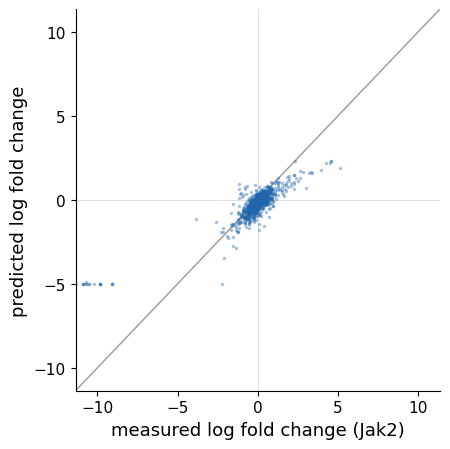

In [7]:
# the scoring modules switch matplotlib to a file backend on import; draw inline here
%matplotlib inline
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(4.6, 4.6))
ax.scatter(obs_lfc[mask], model_lfc[mask], s=6, lw=0, alpha=0.4, color="#2166ac", rasterized=True)
lim = np.nanpercentile(np.abs(np.r_[obs_lfc[mask], model_lfc[mask]]), 99.5)
ax.plot([-lim, lim], [-lim, lim], lw=1, color="0.6", zorder=0)
ax.axhline(0, lw=0.6, color="0.85", zorder=0); ax.axvline(0, lw=0.6, color="0.85", zorder=0)
ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
ax.set_xlabel(f"measured log fold change ({GENE})", fontsize=13)
ax.set_ylabel("predicted log fold change", fontsize=13)
ax.tick_params(labelsize=11)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
fig.tight_layout()
plt.show()

## 6. Score one section with the shipped harness

`run_seen` is what `evaluation/evaluate.sh` calls. Per section it

1. maps the patch file onto model rows and rebuilds the observed matrix in log-CP10K,
2. finds the niches of the held-out patch and the knockout dominating each,
3. decodes every source spot to every panel perturbation, plus the basal slot,
4. restricts scoring to the assay-panel overlap and scores each (niche, knockout) record,
5. writes `lfc_scores.json`, `lfc_agg.json` and the predicted LFC vectors `model_lfc.json` under
   `seen_pert/slide_<n>/`.

The scores the harness writes use the harness reference. The predicted LFCs in `model_lfc.json` are
what the reported numbers are computed from; step 7 rescores them with the disjoint reference.

Note it **skips** a section whose result file already exists - delete the directory to force a
recompute.

In [8]:
%%time
RUN_SECTION_EVAL = True     # False -> read the shipped result instead

if RUN_SECTION_EVAL:
    pmeval.run_seen(args, SECTION)
    scores_path = args.outdir / "seen_pert" / f"slide_{SECTION}" / "lfc_agg.json"
else:
    scores_path = SHIPPED["seen"] / "seen_pert" / f"slide_{SECTION}" / "lfc_agg.json"

agg = json.loads(scores_path.read_text())["L2"]
print("read", rp.show(scores_path), "\n")
pd.DataFrame([{"perturbation": g,
               "lfc_spearman": v["spearman_mean"],
               "lfc_rmse": v["lfc_dist_mean"],
               "n_niches": v["n_niches"],
               "n_scored_genes": v["n_scored_genes"]}
              for g, v in agg.items()]).sort_values("lfc_spearman", ascending=False)

read $CONCERT_NB_WORKDIR/seen_eval/seen_pert/slide_0/lfc_agg.json 

CPU times: user 11.2 s, sys: 517 ms, total: 11.7 s
Wall time: 3.37 s


,perturbation,lfc_spearman,lfc_rmse,n_niches,n_scored_genes
0,Jak2,0.598261,1.135044,2,1053
1,Tgfbr2,0.466816,2.634555,7,1053


## 7. The four sections together

One record is a (knockout, section, niche) triple, exactly as in tutorial 1. The first cell reads
the harness's own per-section scores (harness reference). The second rescores the same predicted LFCs
with the disjoint reference and checks the result against the reported table; that is the number the
paper reports. Point `RESULT_ROOT` at `args.outdir` once you have run step 6 for all four sections.

In [9]:
RESULT_ROOT = SHIPPED["seen"]      # or: WORKDIR / "seen_eval"

records = []
for s in SECTIONS:
    p = RESULT_ROOT / "seen_pert" / f"slide_{s}" / "lfc_scores.json"
    if not p.exists():
        print(f"  section {s}: no result at {rp.show(p)}")
        continue
    for gene, recs in json.loads(p.read_text())["L2"].items():
        for r in recs:
            records.append({"section": s, "perturbation": gene, "niche": r.get("niche"),
                            "lfc_spearman": r["spearman"], "lfc_rmse": r["lfc_dist"],
                            "n_scored_genes": r.get("n_scored_genes")})
pm_seen = pd.DataFrame(records)

print(f"{len(pm_seen)} records over {pm_seen.section.nunique()} sections")
print(f"\nWITHIN-NICHE, harness scores (harness reference)")
print(f"  LFC Spearman : {pm_seen.lfc_spearman.mean():.4f}")
print(f"  LFC RMSE     : {pm_seen.lfc_rmse.mean():.4f}")

pm_seen.groupby("perturbation").agg(n_records=("niche", "size"),
                                    lfc_spearman=("lfc_spearman", "mean"),
                                    lfc_rmse=("lfc_rmse", "mean")).round(4)

31 records over 4 sections

WITHIN-NICHE, harness scores (harness reference)
  LFC Spearman : 0.4498
  LFC RMSE     : 3.0772


,n_records,lfc_spearman,lfc_rmse
perturbation,,,
Ifngr2,6,0.6126,2.5102
Jak2,2,0.5990,1.1344
Tgfbr2,23,0.3944,3.3940


### The reported rule: rescoring with the disjoint reference

The cell below takes CONCERT's predicted LFC vectors from the same result files and scores them
against the disjoint reference, with the function the reported rescore runs. It covers 31 records: its
slide fallback also makes four records scorable that the harness reference leaves unscored (Ifngr2 section 2,
niches `3:0`-`3:2`; Tgfbr2 section 3, `7:0`). The reported benchmark keeps the 27 records shared by
every method (step 9).

In [10]:
def concert_rescored_records(result_root, sections):
    """Rescore CONCERT's stored predicted LFCs with the disjoint reference (score_perturbmap.model_rows)."""
    import anndata as ad
    rpmap.MODEL_METHODS = ["concert"]
    rpm.METHODS["concert"] = (Path(result_root), "CONCERT")
    rows = []
    for s in sections:
        adata = ad.read_h5ad(rpm.PREP / f"slide_{s}.h5ad")
        rows += rpmap.model_rows(adata, s)
    df = pd.DataFrame(rows)
    df = df[df.scored]
    df["record"] = df.gene + "|" + df.slide.astype(str) + "|" + df.niche_key.astype(str)
    return df

mine = concert_rescored_records(RESULT_ROOT, SECTIONS)
rep = pd.read_csv(PM_RESULTS / "pm_seen_lfc_dist_per_record.csv", dtype={"slide": str})
rep = rep[rep.method == "concert"]
rep["record"] = rep.gene + "|" + rep.slide + "|" + rep.niche_key.astype(str)
both = mine.merge(rep, on="record", suffixes=("", "_reported"))
print(f"{len(mine)} CONCERT records rescored; {len(both)} matched to the reported table")
print(f"max |d rho| {np.abs(both.lfc_spearman - both.lfc_spearman_reported).max():.2e}, "
      f"max |d RMSE| {np.abs(both.lfc_dist - both.lfc_dist_reported).max():.2e}")

31 CONCERT records rescored; 31 matched to the reported table
max |d rho| 8.33e-17, max |d RMSE| 4.44e-16


## 8. The cross-slide setting

Here a knockout is masked on its **target** section but kept on at least one donor section, so
the model has to place an effect it has only ever seen elsewhere. Which (knockout, section) pairs
are valid units is fixed by `benchmark/eval_panel.json` - nothing else may be scored as
cross-slide.

The comparison matches the competitors' harness: ground truth is the masked knockout cells on
the target section against the whole-section control population, across the whole section (the
record is registered with `niche = -1`), so CONCERT and the competitors are scored on the same
ground truth.

The cell below lists the valid units and reads the cross-slide scores from
`unseen_pert/slide_<s>/lfc_scores.json` under the shipped cross-slide result directory.

**The cross-slide panel on this assay is tiny**: after the coverage requirements only one section
carries valid units, giving two records in total. Report it with that caveat; two records are too
few to show a trend.

In [11]:
panel_json = json.loads((PM_PREP / "benchmark" / "eval_panel.json").read_text())
print("cross-slide units (gene masked on target section, kept on donors):")
display(pd.DataFrame([{"gene": u["gene"], "target_section": u["target_slide"],
                       "donor_sections": ",".join(map(str, u.get("donor_slides", [])))}
                      for u in panel_json["eval_units"]]))

records = []
for s in SECTIONS:
    p = SHIPPED["unseen"] / "unseen_pert" / f"slide_{s}" / "lfc_scores.json"
    if not p.exists():
        continue
    for gene, recs in json.loads(p.read_text())["L2"].items():
        for r in recs:
            records.append({"section": s, "perturbation": gene,
                            "lfc_spearman": r["spearman"], "lfc_rmse": r["lfc_dist"]})
pm_unseen = pd.DataFrame(records)
print("\nCROSS-SLIDE (code name: unseen)")
print(f"  {len(pm_unseen)} records on {pm_unseen.section.nunique() if len(pm_unseen) else 0} section(s)"
      " -- too few to read a trend into")
print(f"  LFC Spearman : {pm_unseen.lfc_spearman.mean():.4f}")
print(f"  LFC RMSE     : {pm_unseen.lfc_rmse.mean():.4f}")
pm_unseen

cross-slide units (gene masked on target section, kept on donors):


,gene,target_section,donor_sections
0,Ifngr2,1,2
1,Tgfbr2,1,"0,3"



CROSS-SLIDE (code name: unseen)
  2 records on 1 section(s) -- too few to read a trend into
  LFC Spearman : 0.2841
  LFC RMSE     : 1.7177


,section,perturbation,lfc_spearman,lfc_rmse
0,1,Ifngr2,0.193596,2.161211
1,1,Tgfbr2,0.374670,1.274140


To recompute the cross-slide results rather than read them, build the arguments with
`masked_unseen=True` and call the same `run_seen` - the flag switches the ground truth to the masked
cells and the output to `unseen_pert/`:

```python
u_args = pmap_args("unseen", outdir=WORKDIR / "unseen_eval", masked_unseen=True)
units_by_section = pmeval._unseen_units_by_slide(u_args)
for s in SECTIONS:
    units = units_by_section.get(s, [])
    if units:                       # only target sections have units
        pmeval.run_seen(u_args, s, unseen_units=units)
```

## 9. CONCERT next to the published methods and the reference strategies

The reported comparison is in `perturbmap_results/`, every method scored with the disjoint reference:

* `pm_seen_lfc_dist_per_record.csv` - CONCERT and the published methods,
* `pm_seen_naive_baselines_our_rule.csv` - the four reference strategies,
* `pm_seen_state_our_rule.csv` - STATE.

On this assay the comparison is **restricted to the records every method covers**: 27 records
(Tgfbr2 22, Ifngr2 3, Jak2 2). The model methods cover 31, the reference strategies and
STATE the 27; the intersection is the reported record set.

In this table the reported model is the method key **`concert`**. The key
`concert_niche_seen` is an alternative checkpoint, reported in the niche-checkpoint tables.
CellAgentChat cannot be scored on this assay at all - its output blocks are empty.

In [12]:
parts = ["pm_seen_lfc_dist_per_record.csv", "pm_seen_naive_baselines_our_rule.csv",
         "pm_seen_state_our_rule.csv"]
df = pd.concat([pd.read_csv(PM_RESULTS / f, dtype={"slide": str}) for f in parts], ignore_index=True)
df["record"] = df.gene.astype(str) + "|" + df.slide + "|" + df.niche_key.astype(str)

# the reported comparison: CONCERT against the published methods and the reference strategies
sub = df[df.method != "concert_niche_seen"]
covered = sub.groupby("method").record.apply(set)
shared = set.intersection(*covered.tolist())
print(f"{len(shared)} of {sub.record.nunique()} records are covered by every method")
print("per method, before restriction:", {m: len(s) for m, s in covered.items()})

sub = sub[sub.record.isin(shared)]
overall = (sub.groupby(["method", "method_label"])
             .agg(n_records=("record", "size"),
                  lfc_spearman=("lfc_spearman", "mean"),
                  lfc_rmse=("lfc_dist", "mean"))
             .reset_index().sort_values("lfc_spearman", ascending=False))
display(overall.round(4))

stats = pd.read_csv(PM_RESULTS / "perturbmap_seen_concert_vs_competitor_stats.csv")
print("paired Wilcoxon, CONCERT vs each method (BH-adjusted):")
display(stats[["metric", "competitor_label", "n_pairs", "concert_mean", "competitor_mean", "p_adj"]])

per_gene = (sub.groupby(["method_label", "gene"])
              .agg(n=("record", "size"),
                   lfc_spearman=("lfc_spearman", "mean"),
                   lfc_rmse=("lfc_dist", "mean"))
              .reset_index())
per_gene.pivot(index="method_label", columns="gene", values="lfc_spearman").round(3)

27 of 31 records are covered by every method
per method, before restriction: {'biolord': 31, 'celcomen': 31, 'concert': 31, 'gears': 31, 'gex_knn': 27, 'local_knn': 27, 'mean_niche': 27, 'mean_target': 27, 'scgen': 31, 'state': 27, 'steamboat': 31}


,method,method_label,n_records,lfc_spearman,lfc_rmse
2,concert,CONCERT,27,0.4784,3.2446
7,mean_target,Mean target,27,0.3407,4.9547
8,scgen,scGEN,27,0.3398,4.7931
9,state,STATE,27,0.3183,6.8686
0,biolord,Biolord,27,0.2659,4.9548
6,mean_niche,Mean niche,27,0.1624,4.8275
3,gears,GEARS,27,0.0650,4.9649
10,steamboat,Steamboat,27,0.0294,4.8505
4,gex_knn,GEX kNN,27,-0.0016,4.8320
1,celcomen,CelComen,27,-0.0085,10.1908


paired Wilcoxon, CONCERT vs each method (BH-adjusted):


,metric,competitor_label,n_pairs,concert_mean,competitor_mean,p_adj
0,lfc_spearman,scGEN,27,0.478394,0.339757,1.010142e-04
1,lfc_dist,scGEN,27,3.244638,4.793131,2.483527e-08
2,lfc_spearman,Biolord,27,0.478394,0.265871,2.598061e-05
3,lfc_dist,Biolord,27,3.244638,4.954758,2.483527e-08
4,lfc_spearman,GEARS,27,0.478394,0.064970,2.483527e-08
5,lfc_dist,GEARS,27,3.244638,4.964947,2.483527e-08
6,lfc_spearman,Steamboat,27,0.478394,0.029393,2.483527e-08
7,lfc_dist,Steamboat,27,3.244638,4.850530,2.483527e-08
8,lfc_spearman,CelComen,27,0.478394,-0.008543,2.483527e-08
9,lfc_dist,CelComen,27,3.244638,10.190787,2.483527e-08


gene,Ifngr2,Jak2,Tgfbr2
method_label,,,
Biolord,0.213,0.240,0.275
CONCERT,0.445,0.570,0.475
CelComen,-0.010,-0.018,-0.008
GEARS,-0.001,0.006,0.079
GEX kNN,-0.024,0.042,-0.002
Local kNN,-0.196,-0.058,-0.078
Mean niche,0.041,0.057,0.188
Mean target,0.267,0.558,0.331
STATE,0.275,-0.032,0.356


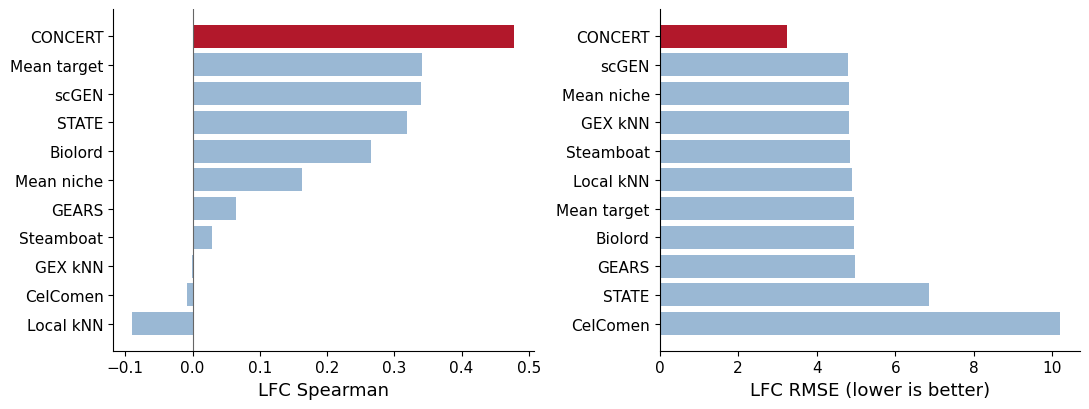

In [13]:
# the scoring modules switch matplotlib to a file backend on import; draw inline here
%matplotlib inline
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
d = overall.sort_values("lfc_spearman")
colors = ["#b2182b" if m == "concert" else "#9ab8d4" for m in d.method]
axes[0].barh(d.method_label, d.lfc_spearman, color=colors)
axes[0].axvline(0, lw=0.8, color="0.4")
axes[0].set_xlabel("LFC Spearman", fontsize=13)

d2 = overall.sort_values("lfc_rmse", ascending=False)
colors2 = ["#b2182b" if m == "concert" else "#9ab8d4" for m in d2.method]
axes[1].barh(d2.method_label, d2.lfc_rmse, color=colors2)
axes[1].set_xlabel("LFC RMSE (lower is better)", fontsize=13)

for ax in axes:
    ax.tick_params(labelsize=11)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
fig.tight_layout()
plt.show()

## What to watch out for

* **Score the assay panel, not all 2000 genes.** The evaluation restricts to the panel overlap.
  Scoring CONCERT's own highly-variable genes inflates the error roughly tenfold against methods
  that score the panel.
* **Use the disjoint reference.** The harness's own `lfc_scores.json` use the harness reference, which
  can contain the held-out source spots themselves. The reported numbers rescore the stored
  predictions with the disjoint reference (`evaluation/aggregate.sh`).
* **Restrict to shared records before comparing methods.** The model methods cover 31 records
  and the reference strategies 27; the reported comparison is the 27-record
  intersection.
* **Band, coordinate scale and inducing count must all match the checkpoint.** The inducing count
  is a saved tensor and would fail loudly, and the loader self-corrects it anyway; the band and
  the coordinate scale fail **silently**.
* **`perturbmap_within_niche` is the reported checkpoint** (the reported arm of the lengthscale sweep).
* **Cross-slide results here rest on two records.** State them with that caveat; they are the
  masked-target scores read in step 8.
* **`seen` / `unseen` are directory names.** In text they are *within-niche prediction* and
  *cross-slide prediction*.

## Where things are

| | |
|---|---|
| model source | `models/concert_benchmark/` |
| scoring code | `benchmark_evaluation/` (`evaluate_concert_perturbmap.py`, `score_perturbmap.py`, `perturbmap_reference.py`) |
| experiment scripts | `experiments/02_perturb_seq_benchmark/` (`evaluation/aggregate.sh`) |
| reported tables | `data/benchmark_assets/results/perturbmap_results/` |